<a href="https://colab.research.google.com/github/saisudhanv/ML-Practice/blob/main/dtreeviz_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install dtreeviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 4.3 MB/s eta 0:00:00


In [2]:
import graphviz.backend as be

In [3]:
from sklearn.datasets import *
from dtreeviz.trees import *
from IPython.display import Image, display_svg, SVG

In [8]:
from sklearn import tree

classi = tree.DecisionTreeClassifier(max_depth=2)
iris = load_iris()

X_train = iris.data
y_train = iris.target

classi.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=2)

[Text(0.4, 0.8333333333333334, 'x[2] <= 2.45\ngini = 0.667\nsamples = 150\nvalue = [50, 50, 50]'),
 Text(0.2, 0.5, 'gini = 0.0\nsamples = 50\nvalue = [50, 0, 0]'),
 Text(0.30000000000000004, 0.6666666666666667, 'True  '),
 Text(0.6, 0.5, 'x[3] <= 1.75\ngini = 0.5\nsamples = 100\nvalue = [0, 50, 50]'),
 Text(0.5, 0.6666666666666667, '  False'),
 Text(0.4, 0.16666666666666666, 'gini = 0.168\nsamples = 54\nvalue = [0, 49, 5]'),
 Text(0.8, 0.16666666666666666, 'gini = 0.043\nsamples = 46\nvalue = [0, 1, 45]')]

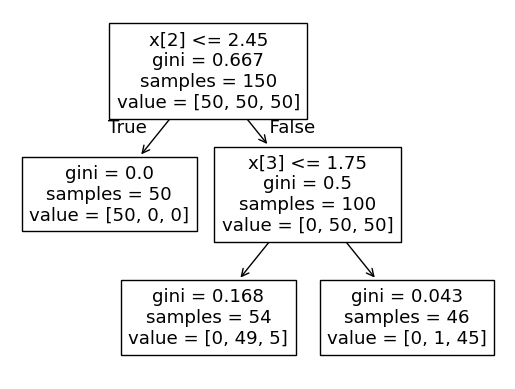

In [9]:
from sklearn.tree import plot_tree
plot_tree(classi)

**1. Classification**

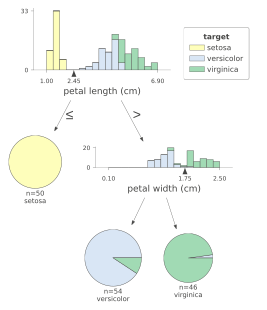

In [13]:
import dtreeviz
from IPython.display import display

viz_model = dtreeviz.model(classi,
                           X_train=X_train,
                           y_train=y_train,
                           target_name="target",
                           feature_names=iris.feature_names,
                           class_names=list(iris.target_names))

# Explicitly display the visualization
display(viz_model.view())

**2. Regression**

In [15]:
from sklearn.datasets import fetch_california_housing
import dtreeviz
from IPython.display import display

regr = tree.DecisionTreeRegressor(max_depth=2)
housing = fetch_california_housing()

X_train = housing.data
y_train = housing.target
regr.fit(X_train, y_train)

viz_model = dtreeviz.model(regr,
                           X_train=X_train,
                           y_train=y_train,
                           target_name='price',
                           feature_names=housing.feature_names
                          )

display(viz_model.view())

**3. Horizontal Decision Tree**

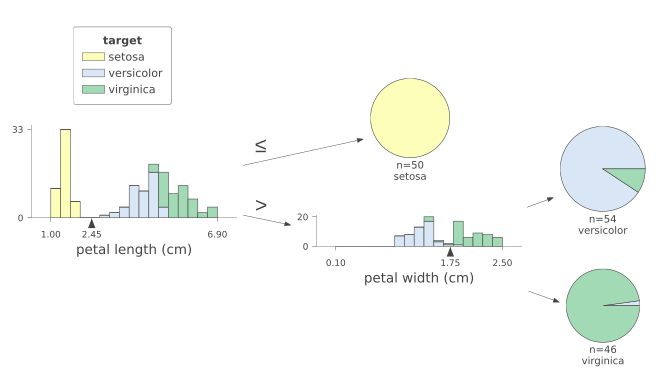

In [18]:
import dtreeviz
from IPython.display import display

# Reload Iris data to ensure X_train and y_train match the classi model
iris = load_iris()
iris_X = iris.data
iris_y = iris.target

viz_model = dtreeviz.model(classi,
                           X_train=iris_X,
                           y_train=iris_y,
                           target_name='target',
                           feature_names=iris.feature_names,
                           class_names=["setosa", "versicolor", "virginica"])

# Render with left-to-right (horizontal) orientation
display(viz_model.view(orientation='LR', scale=1.5))

**4. Show Prediction Path**

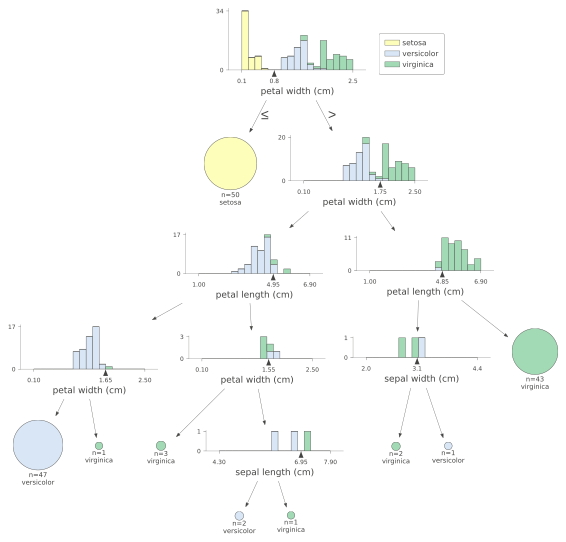

In [22]:
classi = tree.DecisionTreeClassifier()
iris = load_iris()

X_train = iris.data
y_train = iris.target
classi.fit(X_train, y_train)

X = iris.data[np.random.randint(0, len(iris.data)),:]

viz_model = dtreeviz.model(classi,
               X_train,
               y_train,
               feature_names=iris.feature_names,
               class_names=["setosa", "versicolor", "virginica"],
               )
display(viz_model.view())

In [23]:
X

array([4.9, 2.4, 3.3, 1. ])

**5. Show Node number**

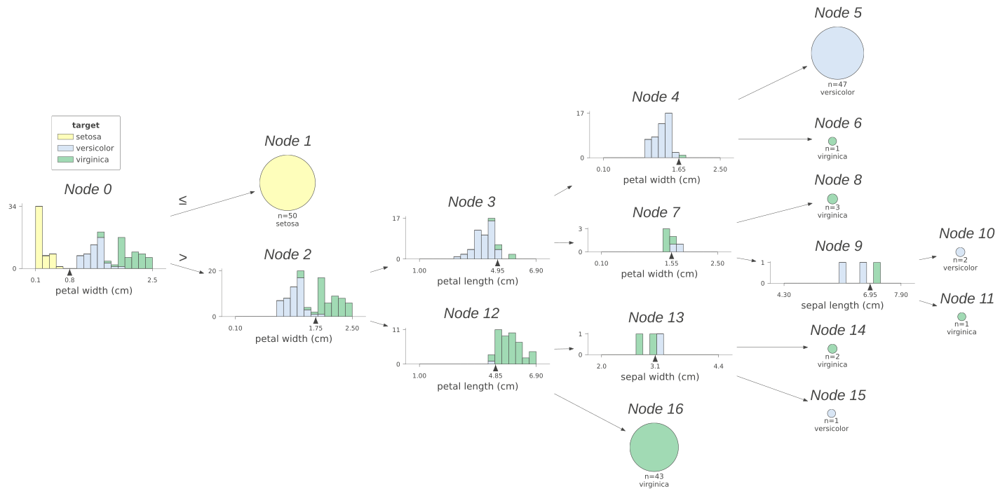

In [28]:
viz_model = dtreeviz.model(classi,
                           X_train,
                           y_train,
                           target_name='target',
                           feature_names=iris.feature_names,
                           class_names=["setosa", "versicolor", "virginica"])

display(viz_model.view(scale=1.5,
                       orientation='LR',
                       show_node_labels=True,
                       histtype='barstacked'))

**6. Without Any Graphs**

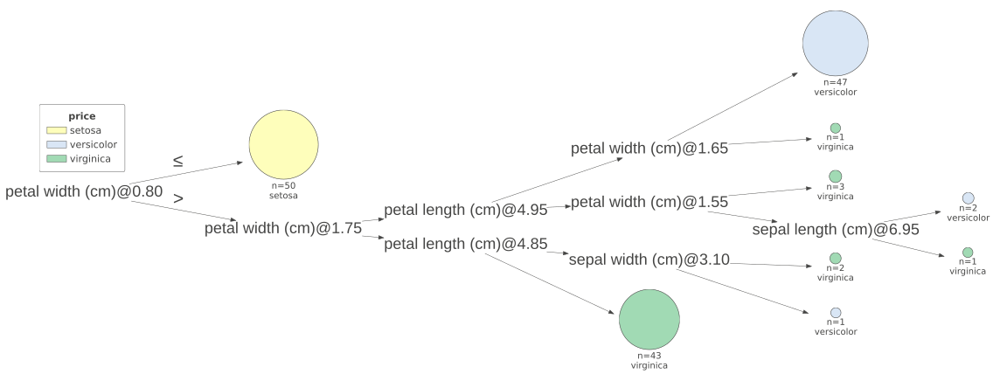

In [30]:
viz_model = dtreeviz.model(classi,
               X_train,
               y_train,
               target_name='price',
               feature_names=iris.feature_names,
               class_names=["setosa", "versicolor", "virginica"]
)

display(viz_model.view(histtype= 'barstacked',
               scale = 1.5,
               orientation='LR',
               fancy=False))

**7. Show just prediction path, nothing else**

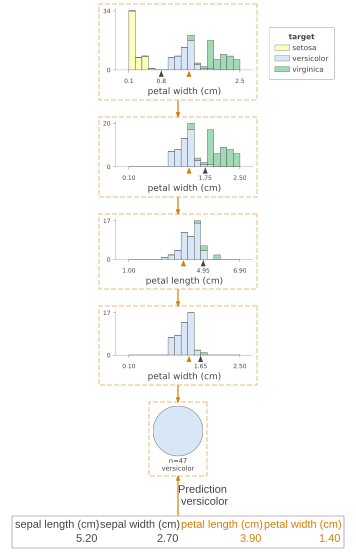

In [32]:
classi = tree.DecisionTreeClassifier()
iris = load_iris()

X_train = iris.data
y_train = iris.target
classi.fit(X_train, y_train)

X = iris.data[np.random.randint(0, len(iris.data)),:]

# Create the model wrapper using the 2.x API
viz_model = dtreeviz.model(classi,
                           X_train,
                           y_train,
                           target_name='target',
                           feature_names=iris.feature_names,
                           class_names=["setosa", "versicolor", "virginica"])

# Highlight the prediction path for sample X
viz = viz_model.view(x=X, show_just_path=True)
display(viz)

**8. Prediction Path in Plain English**

In [34]:
import dtreeviz

# Wrap your trained classifier using the 2.x model API
viz_model = dtreeviz.model(classi,
                           X_train=X_train,
                           y_train=y_train,
                           target_name='target',
                           feature_names=iris.feature_names,
                           class_names=list(iris.target_names))

# Print the prediction path explanation in plain English
print(viz_model.explain_prediction_path(x=X))

petal length (cm) < 4.95
0.8 <= petal width (cm)  < 1.65



**9. Feature Importance**

In [36]:
import dtreeviz

# Wrap your trained classifier using the 2.x model API
viz_model = dtreeviz.model(classi,
                           X_train=X_train,
                           y_train=y_train,
                           target_name='target',
                           feature_names=iris.feature_names,
                           class_names=list(iris.target_names))

# Print the prediction path explanation
print(viz_model.explain_prediction_path(x=X))

petal length (cm) < 4.95
0.8 <= petal width (cm)  < 1.65



**10. Univariate Regression**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names


None

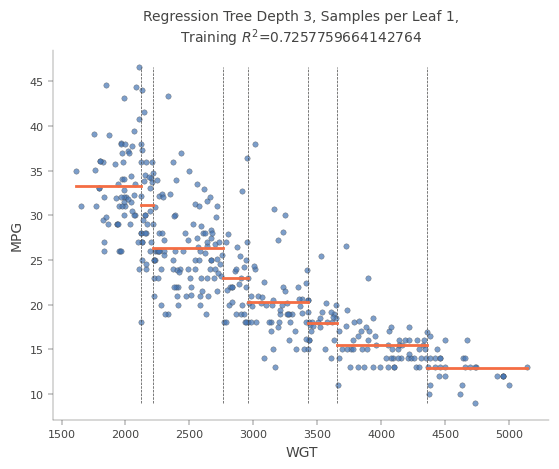

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
import dtreeviz

# Fetch the cars dataset from a public source to fix the FileNotFoundError
url = "https://raw.githubusercontent.com/parrt/dtreeviz/master/data/cars.csv"
df_cars = pd.read_csv(url)

X = df_cars[['WGT']]
y = df_cars['MPG']

# Train the decision tree regressor (using 'absolute_error' since 'mae' is deprecated in scikit-learn)
dt = DecisionTreeRegressor(max_depth=3, criterion="absolute_error")
dt.fit(X, y)

# Use the modern dtreeviz 2.x API for univariate regression space visualization
viz_model = dtreeviz.model(dt,
                           X_train=X,
                           y_train=y,
                           target_name='MPG',
                           feature_names=['WGT'])

# Plot univariate regression feature space correctly without passing a boolean to 'show'
viz = viz_model.rtree_feature_space()
display(viz)

**11. 3-D Regression**

In [41]:
import pandas as pd

# Fetch the cars dataset from a public source
url = "https://raw.githubusercontent.com/parrt/dtreeviz/master/data/cars.csv"
df_cars = pd.read_csv(url)

df_cars

,MPG,CYL,ENG,WGT
0,18.0,8,307.0,3504
1,15.0,8,350.0,3693
2,18.0,8,318.0,3436
3,16.0,8,304.0,3433
4,17.0,8,302.0,3449
...,...,...,...,...
387,27.0,4,140.0,2790
388,44.0,4,97.0,2130
389,32.0,4,135.0,2295
390,28.0,4,120.0,2625


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names


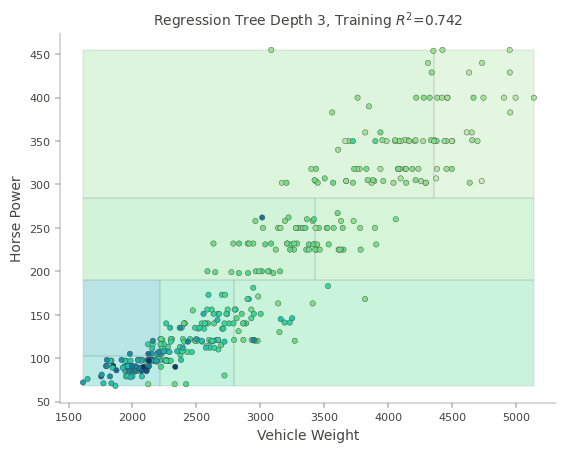

In [48]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
import dtreeviz

X = df_cars[['WGT','ENG']]
y = df_cars['MPG']

# Train the decision tree regressor using modern criteria
dt = DecisionTreeRegressor(max_depth=3, criterion="absolute_error")
dt.fit(X, y)

# Initialize the dtreeviz 2.x API model wrapper
viz_model = dtreeviz.model(dt,
                           X_train=X,
                           y_train=y,
                           feature_names=['Vehicle Weight', 'Horse Power'],
                           target_name='MPG')

# Fix: Let dtreeviz create and manage the figure internally to prevent 3D/2D artist projection mismatches
viz = viz_model.rtree_feature_space(show={'splits','title'})
plt.show()